In [2]:
from __future__ import annotations

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config.config import RUN_DIR

In [28]:
metrics_df = pd.read_csv(RUN_DIR / "all_runs_metrics.csv")
metrics_df.head()

,Experiment,Accuracy,Precision,Recall,F1 Score,Dataset,SubSet,Model,Run
0,direct_entity,0.8392,0.8476,0.9521,0.8968,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
1,direct_entity_ontological,0.8266,0.8495,0.9281,0.8871,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
2,direct_entity_with_synonyms,0.8492,0.8392,0.9829,0.9054,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
3,sequential_hierarchy,0.8442,0.8423,0.9692,0.9013,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
4,sequential_hierarchy_ontological,0.7990,0.8354,0.9041,0.8684,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28


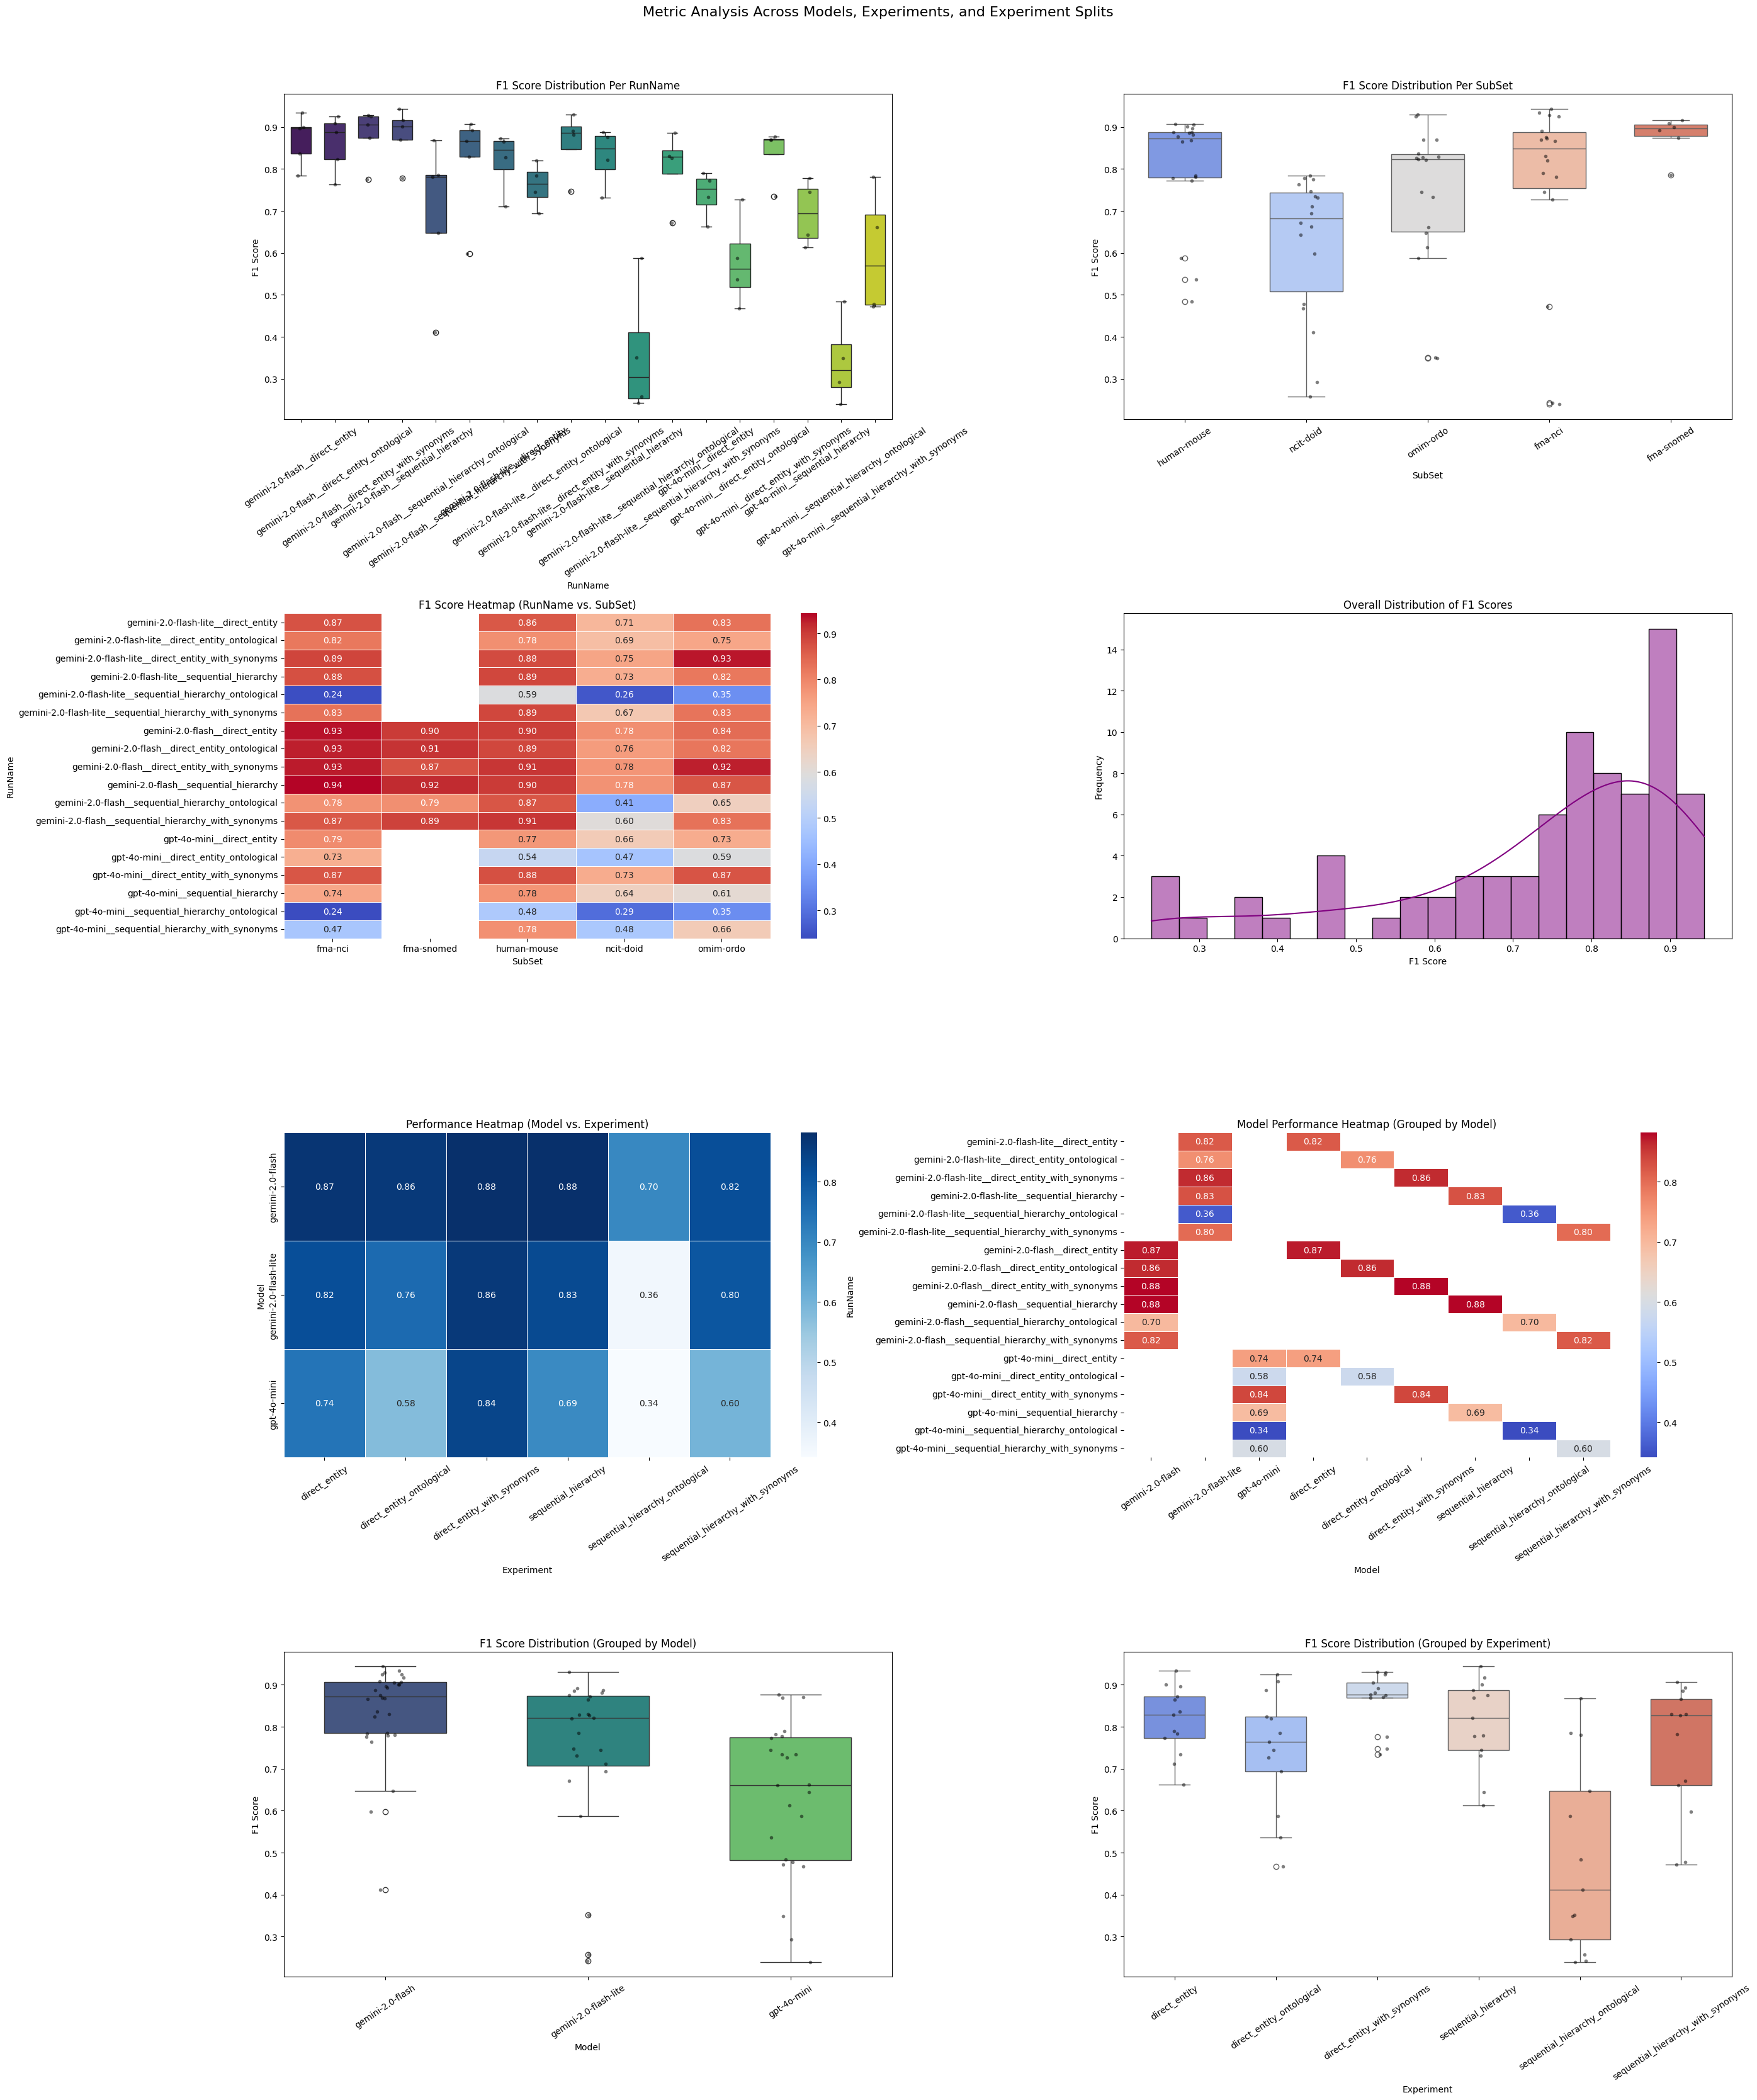

In [30]:
metric = "F1 Score"
# concat Subset and model name

experiment_col, left_col, right_col = 'Experiment', "SubSet", "Model"
experiment_col, left_col, right_col = "SubSet", "Model", 'Experiment'


run_col_name = "RunName"
left_col_name = "leftPart"
right_col_name = "rightPart"
run_separator = "__"

metrics_df[run_col_name] = metrics_df[left_col].str.cat(metrics_df[right_col], sep=run_separator)

metrics_df[left_col_name] = metrics_df[run_col_name].str.split(run_separator).str[0]
metrics_df[right_col_name] = metrics_df[run_col_name].str.split(run_separator).str[1]


fig, axes = plt.subplots(4, 2, figsize=(28, 34))
fig.suptitle("Metric Analysis Across Models, Experiments, and Experiment Splits", fontsize=16)
axes = axes.flatten()

# 1. Box Plot + Points: {metric}s Per Model
sns.boxplot(ax=axes[0], data=metrics_df, x=run_col_name, y=metric, palette="viridis", width=0.6, hue=run_col_name, legend=False)
sns.stripplot(ax=axes[0], data=metrics_df, x=run_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
axes[0].set_title(f"{metric} Distribution Per {run_col_name}")
axes[0].tick_params(axis="x", rotation=34)

# 2. Box Plot + Points: {metric}s Per Experiment Type
sns.boxplot(ax=axes[1], data=metrics_df, x=experiment_col, y=metric, palette="coolwarm", width=0.6, hue=experiment_col, legend=False)
sns.stripplot(ax=axes[1], data=metrics_df, x=experiment_col, y=metric, color="black", alpha=0.5, jitter=True, size=4)
axes[1].set_title(f"{metric} Distribution Per {experiment_col}")
axes[1].tick_params(axis="x", rotation=34)

# 3. Heatmap: Metric Performance (Model vs. Experiment)
pivot_table = metrics_df.pivot_table(index=run_col_name, columns=experiment_col, values=metric, sort=True)
sns.heatmap(ax=axes[2], data=pivot_table, cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5)
axes[2].set_title(f"{metric.title()} Heatmap ({run_col_name} vs. {experiment_col})")
axes[2].set_xlabel(f"{experiment_col}")
axes[2].set_ylabel(f"{run_col_name}")

# 4. Histogram: Overall Distribution of {metric}s
sns.histplot(ax=axes[3], data=metrics_df[metric], bins=20, kde=True, color="purple")
axes[3].set_title(f"Overall Distribution of {metric}s")
axes[3].set_xlabel(f"{metric}")
axes[3].set_ylabel("Frequency")

# 5. Heatmap: Metric Performance ({left_col} vs. {right_col})
pivot_table_lr = metrics_df.pivot_table(index=left_col_name, columns=right_col_name, values=metric)
sns.heatmap(ax=axes[4], data=pivot_table_lr, cmap="Blues", annot=True, fmt=".2f", linewidths=0.5)
axes[4].set_title(f"Performance Heatmap ({left_col} vs. {right_col})")
axes[4].set_xlabel(f"{right_col}")
axes[4].set_ylabel(f"{left_col}")
axes[4].tick_params(axis="x", rotation=34)

# 6. Heatmap: Model Performance by Left & {right_col}
pivot_table_left = metrics_df.pivot_table(index=run_col_name, columns=left_col_name, values=metric)
pivot_table_right = metrics_df.pivot_table(index=run_col_name, columns=right_col_name, values=metric)
combined = pd.concat([pivot_table_left, pivot_table_right], axis=1)

sns.heatmap(ax=axes[5], data=combined, cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5)
axes[5].set_title(f"Model Performance Heatmap (Grouped by {left_col})")
axes[5].set_xlabel(f"{left_col}")
axes[5].set_ylabel(f"{run_col_name}")
axes[5].tick_params(axis="x", rotation=34)

# 7. Box Plot: {metric}s Grouped by {left_col}
sns.boxplot(ax=axes[6], data=metrics_df, x=left_col_name, y=metric, palette="viridis", width=0.6, hue=left_col_name, legend=False)
sns.stripplot(ax=axes[6], data=metrics_df, x=left_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
axes[6].set_title(f"{metric} Distribution (Grouped by {left_col})")
axes[6].set_xlabel(f"{left_col}")

axes[6].tick_params(axis="x", rotation=34)

# 8. Box Plot: {metric}s Grouped by {right_col}
sns.boxplot(ax=axes[7], data=metrics_df, x=right_col_name, y=metric, palette="coolwarm", width=0.6, hue=right_col_name, legend=False)
sns.stripplot(ax=axes[7], data=metrics_df, x=right_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
axes[7].set_title(f"{metric} Distribution (Grouped by {right_col})")
axes[7].set_xlabel(f"{right_col}")
axes[7].tick_params(axis="x", rotation=34)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()